In [38]:
import pandas as pd

# Load dataset
df = pd.read_csv("cleaned_olympics.csv")

# Check dataset
print(df.head())

# Statistical summary
print("Dataset Shape:", df.shape)

display(df.describe())

display(df.describe(include='object'))

   ID                      Name Sex   Age  Height  Weight            Team  \
0   1                 A Dijiang   M  24.0   180.0    80.0           China   
1   2                  A Lamusi   M  23.0   170.0    60.0           China   
2   3       Gunnar Nielsen Aaby   M  24.0   175.0    70.0         Denmark   
3   4      Edgar Lindenau Aabye   M  34.0   175.0    70.0  Denmark/Sweden   
4   5  Christine Jacoba Aaftink   F  21.0   185.0    82.0     Netherlands   

   NOC        Games  Year  Season       City          Sport  \
0  CHN  1992 Summer  1992  Summer  Barcelona     Basketball   
1  CHN  2012 Summer  2012  Summer     London           Judo   
2  DEN  1920 Summer  1920  Summer  Antwerpen       Football   
3  DEN  1900 Summer  1900  Summer      Paris     Tug-Of-War   
4  NED  1988 Winter  1988  Winter    Calgary  Speed Skating   

                              Event     Medal  
0       Basketball Men's Basketball  No Medal  
1      Judo Men's Extra-Lightweight  No Medal  
2           Fo

,ID,Age,Height,Weight,Year
count,269731.000000,269731.000000,269731.000000,269731.000000,269731.000000
mean,68264.949591,25.404536,175.265046,70.541699,1978.623073
std,39026.253843,6.062324,9.302366,12.610136,29.752055
min,1.000000,10.000000,127.000000,25.000000,1896.000000
25%,34655.500000,22.000000,170.000000,63.000000,1960.000000
50%,68233.000000,24.000000,175.000000,70.000000,1988.000000
75%,102111.000000,28.000000,180.000000,76.000000,2002.000000
max,135571.000000,97.000000,226.000000,214.000000,2016.000000


<ipython-input-38-987035adce26>:14: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include='object'))


,Name,Sex,Team,NOC,Games,Season,City,Sport,Event,Medal
count,269731,269731,269731,269731,269731,269731,269731,269731,269731,269731
unique,134732,2,1184,230,51,2,42,66,765,4
top,Heikki Ilmari Savolainen,M,United States,USA,2000 Summer,Summer,London,Athletics,Football Men's Football,No Medal
freq,39,195353,17598,18604,13821,221167,22297,38624,5733,229959


In [39]:
%pip install seaborn

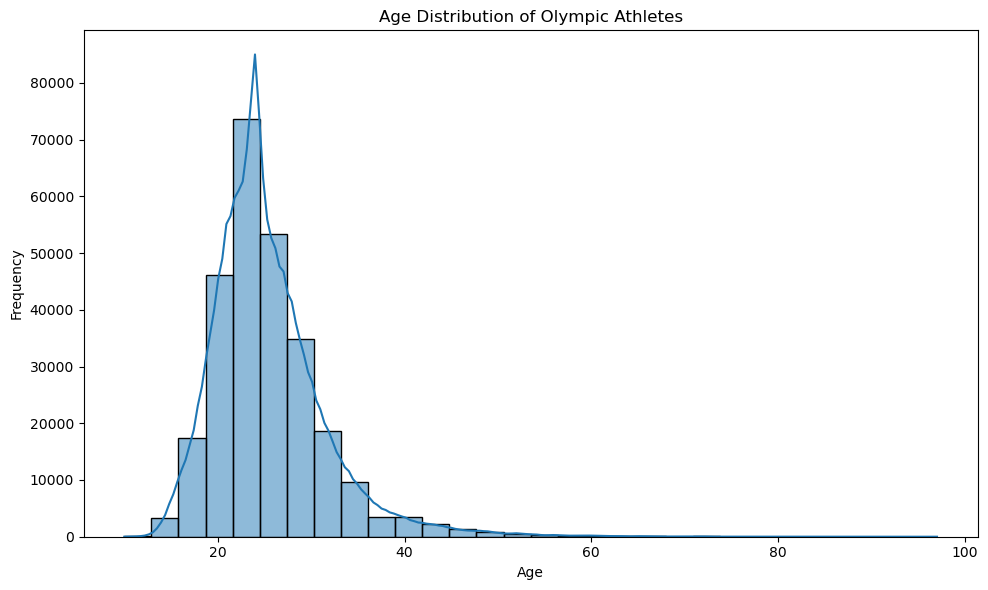

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='Age',
    bins=30,
    kde=True
)

plt.title('Age Distribution of Olympic Athletes')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

In [44]:
import pandas as pd

df = pd.read_csv("cleaned_olympics.csv")
gender_counts = df['Sex'].value_counts()

print(gender_counts)

Sex
M    195353
F     74378
Name: count, dtype: int64


In [45]:
%pip install seaborn

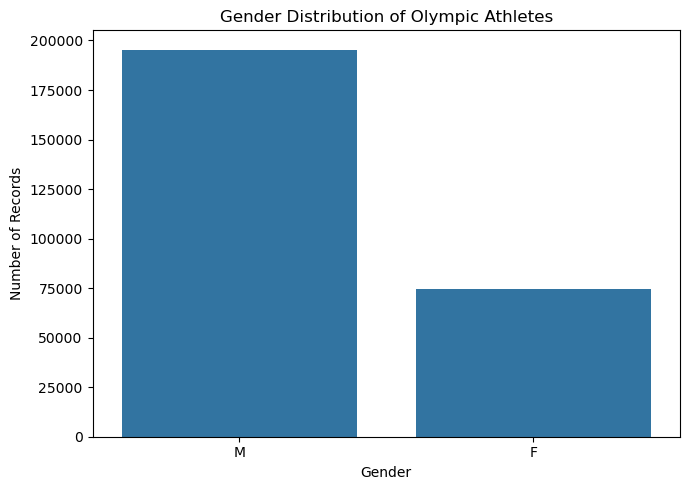

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Sex'
)

plt.title('Gender Distribution of Olympic Athletes')
plt.xlabel('Gender')
plt.ylabel('Number of Records')

plt.tight_layout()
plt.show()

In [47]:
import pandas as pd

df = pd.read_csv("cleaned_olympics.csv")

print("Dataset loaded!")
print("Shape:", df.shape)
print(df.columns.tolist())
gender_year = df.groupby(
    ['Year', 'Sex']
)['Name'].nunique().reset_index()

gender_year.head()

Dataset loaded!
Shape: (269731, 15)
['ID', 'Name', 'Sex', 'Age', 'Height', 'Weight', 'Team', 'NOC', 'Games', 'Year', 'Season', 'City', 'Sport', 'Event', 'Medal']


,Year,Sex,Name
0,1896,M,176
1,1900,F,23
2,1900,M,1197
3,1904,F,6
4,1904,M,644


In [48]:
import pandas as pd

df = pd.read_csv("cleaned_olympics.csv")

print(df.shape)
gender_pivot = gender_year.pivot(
    index='Year',
    columns='Sex',
    values='Name'
)

gender_pivot.head()

(269731, 15)


Sex,F,M
Year,,
1896,NaN,176.0
1900,23.0,1197.0
1904,6.0,644.0
1906,6.0,835.0
1908,44.0,1980.0


In [49]:
import pandas as pd

df = pd.read_csv("cleaned_olympics.csv")

print(df.shape)
gender_pivot['Gender_Gap'] = (
    gender_pivot.get('M', 0)
    - gender_pivot.get('F', 0)
)

gender_pivot.tail()

(269731, 15)


Sex,F,M,Gender_Gap
Year,,,
2008,4603.0,6284.0,1681.0
2010,1032.0,1503.0,471.0
2012,4646.0,5858.0,1212.0
2014,1102.0,1642.0,540.0
2016,5031.0,6143.0,1112.0


In [50]:
import pandas as pd

df = pd.read_csv("cleaned_olympics.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
medal_counts = df['Medal'].value_counts()

print(medal_counts)

Dataset loaded successfully!
Shape: (269731, 15)
Medal
No Medal    229959
Gold         13369
Bronze       13295
Silver       13108
Name: count, dtype: int64


In [51]:
import pandas as pd

df = pd.read_csv("cleaned_olympics.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
medal_percentage = (
    df['Medal']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(medal_percentage)

Dataset loaded successfully!
Shape: (269731, 15)
Medal
No Medal    85.25
Gold         4.96
Bronze       4.93
Silver       4.86
Name: proportion, dtype: float64


In [52]:
import pandas as pd

df = pd.read_csv("cleaned_olympics.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
medal_df = df[df['Medal'] != 'No Medal'].copy()

print("Total medal records:", len(medal_df))

Dataset loaded successfully!
Shape: (269731, 15)
Total medal records: 39772


In [53]:
medal_df = df[df['Medal'] != 'No Medal'].copy()

print("Medal records:", len(medal_df))
medal_type_percentage = (
    medal_df['Medal']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(medal_type_percentage)

Medal records: 39772
Medal
Gold      33.61
Bronze    33.43
Silver    32.96
Name: proportion, dtype: float64


In [54]:
medal_df = df[df['Medal'] != 'No Medal'].copy()

print("Medal records:", len(medal_df))
country_medals = (
    medal_df
    .groupby('NOC')['Medal']
    .count()
    .sort_values(ascending=False)
)

print(country_medals.head(20))

Medal records: 39772
NOC
USA    5637
URS    2503
GER    2165
GBR    2067
FRA    1767
ITA    1637
SWE    1536
CAN    1352
AUS    1320
RUS    1165
HUN    1135
NED    1040
NOR    1033
GDR    1005
CHN     989
JPN     913
FIN     900
SUI     691
ROU     653
KOR     638
Name: Medal, dtype: int64


In [55]:
import pandas as pd
country_medal_table = pd.DataFrame({
    'Total_Medals': country_medals,
    'Percentage': (
        country_medals /
        country_medals.sum() * 100
    ).round(2)
})

country_medal_table.head(20)

,Total_Medals,Percentage
NOC,,
USA,5637,14.17
URS,2503,6.29
GER,2165,5.44
GBR,2067,5.20
FRA,1767,4.44
ITA,1637,4.12
SWE,1536,3.86
CAN,1352,3.40
AUS,1320,3.32


In [56]:
medal_df = df[df['Medal'] != 'No Medal'].copy()

print("Medal records:", len(medal_df))
sport_medals = (
    medal_df
    .groupby('Sport')['Medal']
    .count()
    .sort_values(ascending=False)
)

print(sport_medals.head(20))

Medal records: 39772
Sport
Athletics               3969
Swimming                3048
Rowing                  2945
Gymnastics              2256
Fencing                 1743
Football                1571
Ice Hockey              1530
Hockey                  1528
Wrestling               1296
Cycling                 1263
Shooting                1228
Sailing                 1221
Canoeing                1165
Basketball              1080
Handball                1060
Water Polo              1057
Volleyball               969
Equestrianism            965
Boxing                   944
Cross Country Skiing     776
Name: Medal, dtype: int64


In [57]:
import pandas as pd
sport_medal_table = pd.DataFrame({
    'Total_Medals': sport_medals,
    'Percentage': (
        sport_medals /
        sport_medals.sum() * 100
    ).round(2)
})

sport_medal_table.head(20)

,Total_Medals,Percentage
Sport,,
Athletics,3969,9.98
Swimming,3048,7.66
Rowing,2945,7.40
Gymnastics,2256,5.67
Fencing,1743,4.38
Football,1571,3.95
Ice Hockey,1530,3.85
Hockey,1528,3.84
Wrestling,1296,3.26


In [58]:
medal_df = df[df['Medal'] != 'No Medal'].copy()

print("Medal records:", len(medal_df))
medal_df['Decade'] = (
    medal_df['Year'] // 10
) * 10

Medal records: 39772


In [60]:
medal_df['Decade'] = (medal_df['Year'] // 10) * 10
decade_medals = (
    medal_df
    .groupby('Decade')['Medal']
    .count()
)

print(decade_medals)

Decade
1890     143
1900    2368
1910     941
1920    3093
1930    1764
1940     987
1950    2076
1960    3529
1970    2945
1980    5145
1990    4643
2000    7057
2010    5081
Name: Medal, dtype: int64


In [61]:
medal_df['Decade'] = (medal_df['Year'] // 10) * 10
decade_percentage = (
    decade_medals /
    decade_medals.sum() * 100
).round(2)

print(decade_percentage)

Decade
1890     0.36
1900     5.95
1910     2.37
1920     7.78
1930     4.44
1940     2.48
1950     5.22
1960     8.87
1970     7.40
1980    12.94
1990    11.67
2000    17.74
2010    12.78
Name: Medal, dtype: float64


In [62]:
import pandas as pd
country_medal_type = pd.crosstab(
    medal_df['NOC'],
    medal_df['Medal']
)

country_medal_type['Total'] = (
    country_medal_type.sum(axis=1)
)

country_medal_type = country_medal_type.sort_values(
    'Total',
    ascending=False
)

country_medal_type.head(15)

Medal,Bronze,Gold,Silver,Total
NOC,,,,
USA,1358,2638,1641,5637
URS,689,1082,732,2503
GER,746,745,674,2165
GBR,651,677,739,2067
FRA,666,499,602,1767
ITA,531,575,531,1637
SWE,535,479,522,1536
CAN,451,463,438,1352
AUS,517,348,455,1320


In [63]:
import pandas as pd
sport_medal_type = pd.crosstab(
    medal_df['Sport'],
    medal_df['Medal']
)

sport_medal_type['Total'] = (
    sport_medal_type.sum(axis=1)
)

sport_medal_type = sport_medal_type.sort_values(
    'Total',
    ascending=False
)

sport_medal_type.head(15)

Medal,Bronze,Gold,Silver,Total
Sport,,,,
Athletics,1296,1339,1334,3969
Swimming,956,1099,993,3048
Rowing,990,978,977,2945
Gymnastics,719,791,746,2256
Fencing,566,594,583,1743
Football,543,515,513,1571
Ice Hockey,507,508,515,1530
Hockey,512,518,498,1528
Wrestling,468,413,415,1296


In [65]:
import pandas as pd
import numpy as np

numeric_cols = df.select_dtypes(include='number')
print("Numerical columns:")
print(numeric_cols.columns.tolist())

correlation_matrix = numeric_cols.corr()
print("\nCorrelation Matrix:")
display(correlation_matrix)

Numerical columns:
['ID', 'Age', 'Height', 'Weight', 'Year']

Correlation Matrix:


,ID,Age,Height,Weight,Year
ID,1.000000,-0.002580,-0.009612,-0.007715,0.011381
Age,-0.002580,1.000000,0.109734,0.165544,-0.073950
Height,-0.009612,0.109734,1.000000,0.786701,0.039883
Weight,-0.007715,0.165544,0.786701,1.000000,0.027158
Year,0.011381,-0.073950,0.039883,0.027158,1.000000


In [66]:
%pip install seaborn


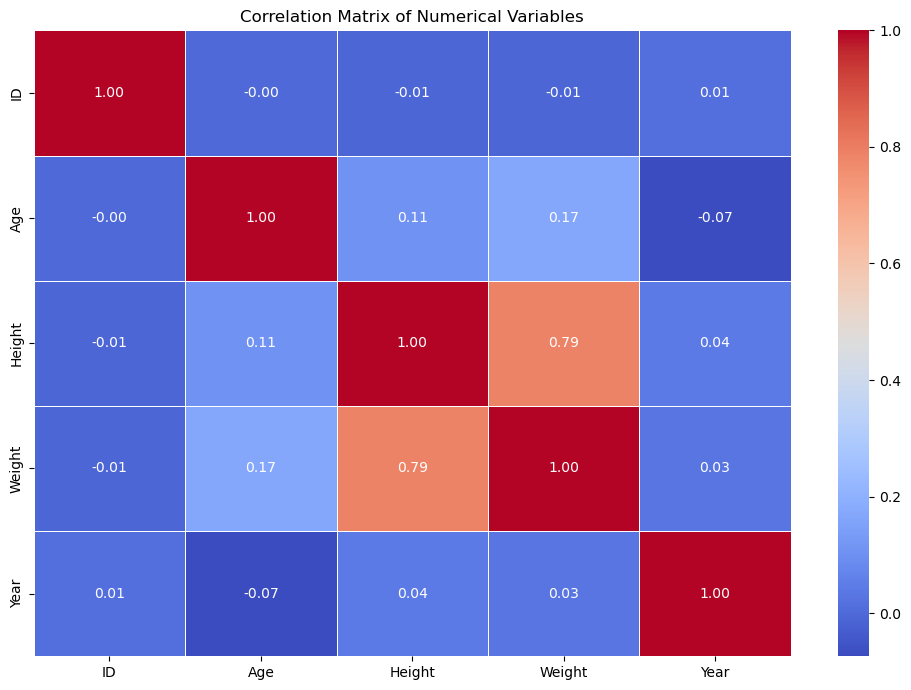

In [67]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Matrix of Numerical Variables')

plt.tight_layout()
plt.show()

In [69]:
import pandas as pd

df = pd.read_csv("cleaned_olympics.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print(df.columns.tolist())
age_stats = df['Age'].describe()

height_stats = df['Height'].describe()

print("Age Statistics:")
print(age_stats)

print("\nHeight Statistics:")
print(height_stats)

Dataset loaded successfully!
Shape: (269731, 15)
['ID', 'Name', 'Sex', 'Age', 'Height', 'Weight', 'Team', 'NOC', 'Games', 'Year', 'Season', 'City', 'Sport', 'Event', 'Medal']
Age Statistics:
count    269731.000000
mean         25.404536
std           6.062324
min          10.000000
25%          22.000000
50%          24.000000
75%          28.000000
max          97.000000
Name: Age, dtype: float64

Height Statistics:
count    269731.000000
mean        175.265046
std           9.302366
min         127.000000
25%         170.000000
50%         175.000000
75%         180.000000
max         226.000000
Name: Height, dtype: float64


In [26]:
def detect_outliers_iqr(data, column):

    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    return outliers, lower_bound, upper_bound

In [70]:
import pandas as pd

df = pd.read_csv("cleaned_olympics.csv")

print("Dataset loaded:", df.shape)
age_outliers, age_lower, age_upper = detect_outliers_iqr(
    df,
    'Age'
)

print("Age Lower Bound:", age_lower)
print("Age Upper Bound:", age_upper)

print("Number of Age Outliers:", len(age_outliers))

Dataset loaded: (269731, 15)
Age Lower Bound: 13.0
Age Upper Bound: 37.0
Number of Age Outliers: 11059


In [71]:
print("Dataset shape:", df.shape)
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    return outliers, lower_bound, upper_bound
age_outliers, age_lower, age_upper = detect_outliers_iqr(
    df,
    'Age'
)
print("Age Lower Bound:", age_lower)
print("Age Upper Bound:", age_upper)
print("Number of Age Outliers:", len(age_outliers))
age_outlier_percentage = (
    len(age_outliers) / len(df) * 100
)

print(f"Age Outlier Percentage: {age_outlier_percentage:.2f}%")

Dataset shape: (269731, 15)
Age Lower Bound: 13.0
Age Upper Bound: 37.0
Number of Age Outliers: 11059
Age Outlier Percentage: 4.10%


In [72]:
import pandas as pd

df = pd.read_csv("cleaned_olympics.csv")
height_outliers, height_lower, height_upper = detect_outliers_iqr(
    df,
    'Height'
)

print("Height Lower Bound:", height_lower)
print("Height Upper Bound:", height_upper)

print("Number of Height Outliers:", len(height_outliers))

Height Lower Bound: 155.0
Height Upper Bound: 195.0
Number of Height Outliers: 10529


In [73]:
import pandas as pd

df = pd.read_csv("cleaned_olympics.csv")
weight_outliers, weight_lower, weight_upper = detect_outliers_iqr(
    df,
    'Weight'
)

print("Weight Lower Bound:", weight_lower)
print("Weight Upper Bound:", weight_upper)

print("Number of Weight Outliers:", len(weight_outliers))

Weight Lower Bound: 43.5
Weight Upper Bound: 95.5
Number of Weight Outliers: 12294


In [74]:
import pandas as pd
outlier_summary = pd.DataFrame({
    'Variable': ['Age', 'Height', 'Weight'],
    'Outliers': [
        len(age_outliers),
        len(height_outliers),
        len(weight_outliers)
    ],
    'Percentage': [
        len(age_outliers) / len(df) * 100,
        len(height_outliers) / len(df) * 100,
        len(weight_outliers) / len(df) * 100
    ]
})

outlier_summary['Percentage'] = (
    outlier_summary['Percentage'].round(2)
)

outlier_summary

,Variable,Outliers,Percentage
0,Age,11059,4.10
1,Height,10529,3.90
2,Weight,12294,4.56


In [75]:
%pip install seaborn

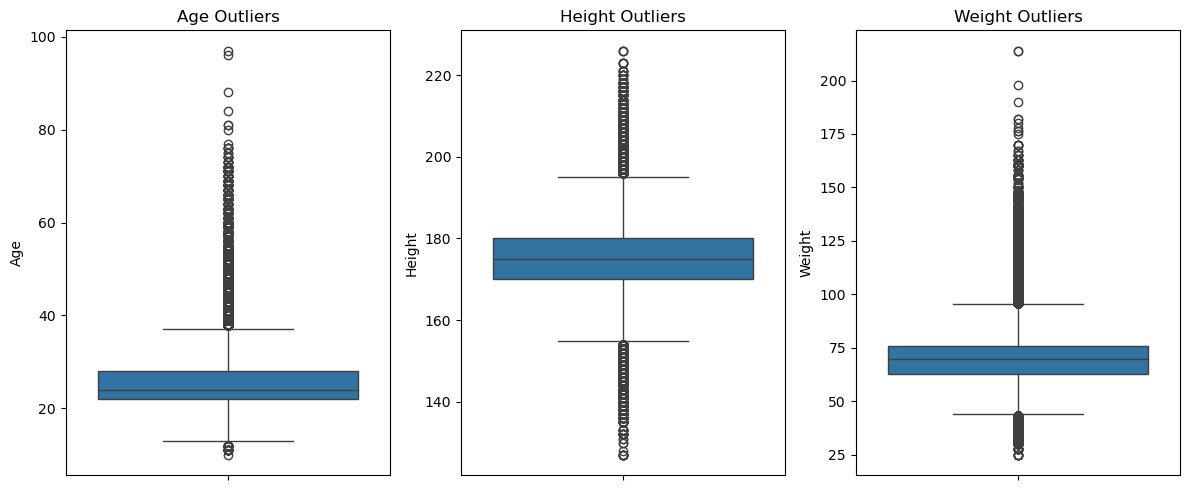

In [76]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
sns.boxplot(y=df['Age'])
plt.title('Age Outliers')

plt.subplot(1, 3, 2)
sns.boxplot(y=df['Height'])
plt.title('Height Outliers')

plt.subplot(1, 3, 3)
sns.boxplot(y=df['Weight'])
plt.title('Weight Outliers')

plt.tight_layout()
plt.show()

In [12]:
%pip install seaborn

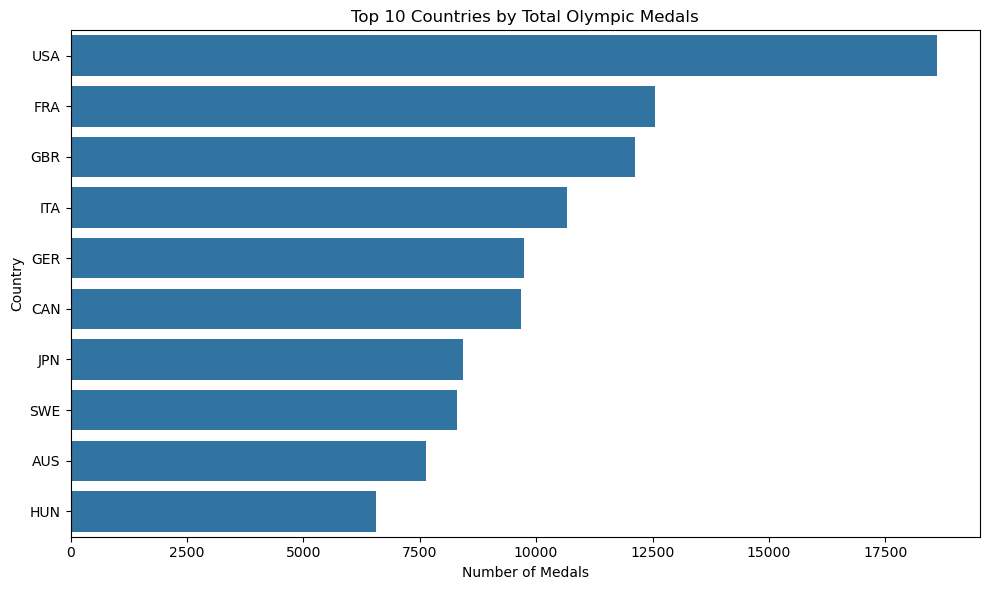

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv("cleaned_olympics.csv")
country_medals = df['NOC'].value_counts()

country_medals.head(10)
top_countries = country_medals.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Top 10 Countries by Total Olympic Medals")
plt.xlabel("Number of Medals")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

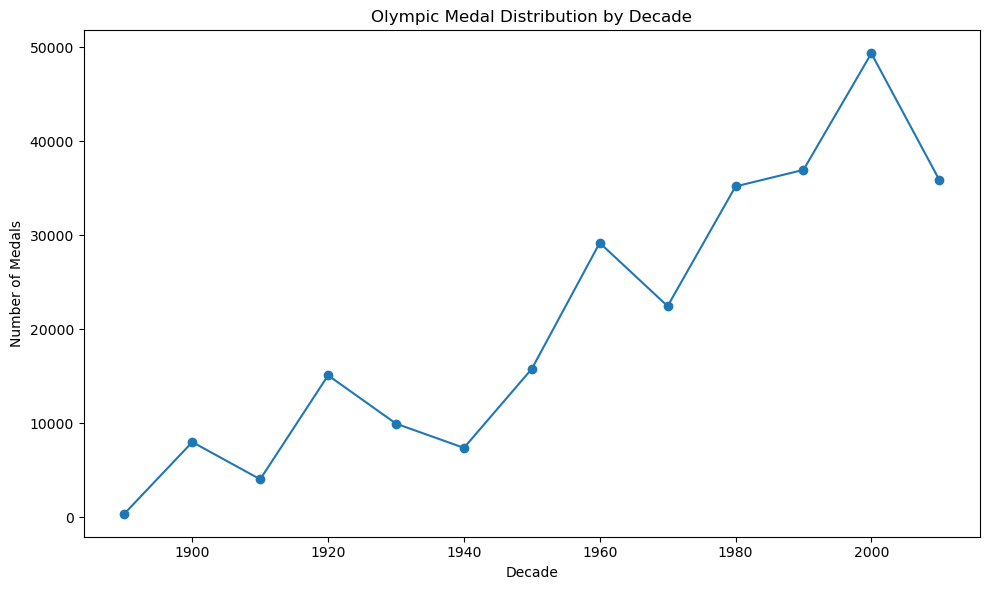

In [20]:
import matplotlib.pyplot as plt
import pandas as pd

df['decade'] = (df['Year'] // 10) * 10

decade_medals = df.groupby('decade')['Medal'].count()
plt.figure(figsize=(10, 6))

plt.plot(
    decade_medals.index,
    decade_medals.values,
    marker='o'
)

plt.title("Olympic Medal Distribution by Decade")
plt.xlabel("Decade")
plt.ylabel("Number of Medals")

plt.tight_layout()
plt.show()

In [21]:
%pip install seaborn

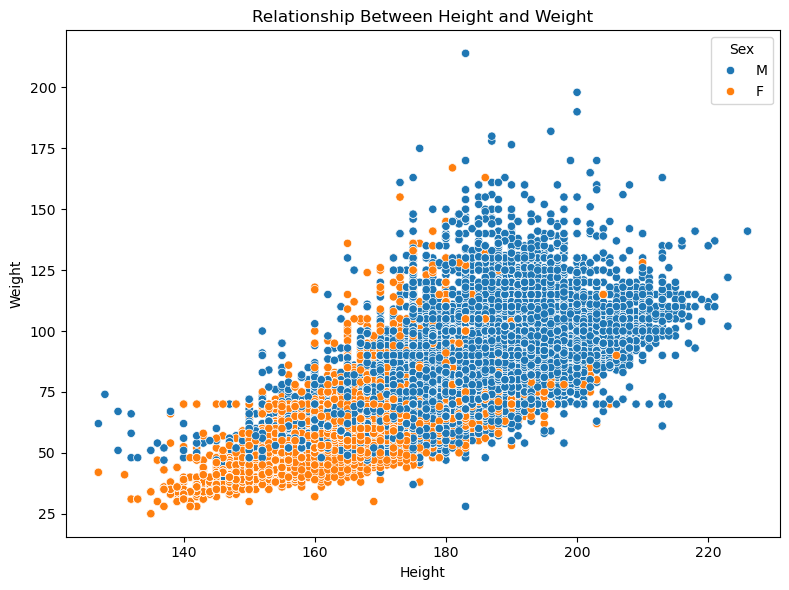

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='Height',
    y='Weight',
    hue='Sex'
)

plt.title("Relationship Between Height and Weight")
plt.xlabel("Height")
plt.ylabel("Weight")

plt.tight_layout()
plt.show()